<a href="https://colab.research.google.com/github/germanricardovilla-collab/everpeak-analysis/blob/main/everpeak_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
# Cargar el dataset desde una URL en JupyterLite (Try Jupyter)
# JupyterLite ejecuta Python dentro del navegador (Pyodide), y el navegador
# no permite que pandas se conecte a internet directamente.
# Por eso pd.read_csv(url) genera error en este entorno.
url_clean = "https://practicum-content.s3.us-west-1.amazonaws.com/datasets/everpeak_clean.csv"

In [12]:
# 1. open_url(url) le pide al navegador que descargue el CSV y lo devuelve como texto en memoria
# 2. pd.read_csv() lee ese texto como si fuera un archivo local y crea el DataFrame
df = pd.read_csv(url_clean)
df.head()

,order_id,order_date,customer_id,product_category,price,quantity,order_value,payment_method,city,state,customer_age,quantity_invalid_flag,age_invalid_flag,state_missing_flag
0,1,2024-02-02,2616,Sports,269,50,13385,credit_card,New York,NY,66,0,0,0
1,2,2024-10-10,1736,Grocery,66,10,660,debit_card,Los Angeles,CA,24,1,0,0
2,3,2024-08-27,2543,Sports,267,19,5073,credit_card,Chicago,IL,23,1,0,0
3,4,2024-06-09,2252,Toys,114,125,14290,credit_card,New York,NY,70,0,0,0
4,5,2024-06-07,1583,Fashion,729,16,11754,credit_card,Houston,TX,75,0,0,0


In [13]:
print(df.shape)

(5000, 14)


In [14]:
#Conteo de valores faltantes por columna
#Objetivo: Contar cuántos valores faltantes tiene cada variable de segmentación y ubicación, usando sumas, no porcentajes

payment_missing = df['payment_method'].isna().sum()# Tu código aquí
city_missing = df['city'].isna().sum()# Tu código aquí
state_missing = df['state'].isna().sum()# Tu código aquí

print("payment_method missing:", payment_missing)
print("city missing:", city_missing)
print("state missing:", state_missing)

payment_method missing: 0
city missing: 0
state missing: 0


In [15]:
#Fechas sospechosas y montos extremos#Objetivo: Medir cuántos registros tienen fechas sospechosas y montos anormalmente altos
#Objetivo: Medir cuántos registros tienen fechas sospechosas y montos anormalmente altos
df["order_date"] =  pd.to_datetime(df["order_date"], errors="coerce")#Tu Código aquí

invalid_year_2026_count = (df["order_date"].dt.year == 2026).sum()#Tu Código aquí
missing_order_date_count = df["order_date"].isna().sum()#Tu Código aquí

print("order_date año 2026:", invalid_year_2026_count)
print("order_date missing:", missing_order_date_count)

order_date año 2026: 15
order_date missing: 0


In [16]:
#Cardinalidad en columnas de cliente
#Objetivo: Calcular la cardinalidad de columnas clave para entender si son IDs, categorías o variables poco útiles.


customer_id_unicos = df['customer_id'].nunique()# cardinalidad altisima
payment_unicos =df['payment_method'].nunique()  # cardinalidad baja
city_unicos = df['city'].nunique() # cardinalidad baja
state_unicos = df['state'].nunique() # cardinalidad baja

print("customer_id nunique:", customer_id_unicos)
print("payment_method nunique:", payment_unicos)
print("city nunique:", city_unicos)

customer_id nunique: 1829
payment_method nunique: 4
city nunique: 11


In [17]:
#Detectar patrones de missingness por grupo
#Objetivo: Evaluar si el missing de city depende de alguna variable del negocio.


missing_city_by_pay = df['city'].isna().groupby(df['payment_method']).mean().sort_values(ascending=False)#tu código aquí
print(missing_city_by_pay)

payment_method
cash           0.0
credit_card    0.0
debit_card     0.0
paypal         0.0
Name: city, dtype: float64


In [18]:
#Comparar impacto entre drop e imputación
#Objetivo: Medir cómo cambia la métrica cuando imputas o eliminas datos.

before = df['order_value'].dropna().mean() # calcula la media original aquí
df["order_value_imputed"] = df['order_value'].fillna(df['order_value'].median())# tu código para imputar aquí
after = df['order_value_imputed'].dropna().mean() # calcula la media después de imputar aquí

print(before)
print(after)

10075.5238
10075.5238


In [19]:
#Objetivo: Comparar tres versiones de una columna numérica para decidir la estrategia final.


print(df['customer_age'].isna().sum())
before = df['customer_age'].mean()# Tu código aquí

# Creamos "customer_age_med"
df["customer_age_med"] = df['customer_age'].fillna(df['customer_age'].median())# Tu código aquí
after_med = df['customer_age_med'].dropna().median()# calcula la media aquí

# Creamos "customer_age_mean"
df["customer_age_mean"] = df['customer_age'].fillna(df['customer_age'].mean())# Tu código aquí
after_mean = df['customer_age_mean'].dropna().mean()# calcula la media aquí

print(before)
print(after_med)
print(after_mean)
print('es mas apropiado imputar con la mediana debido a que presenta menor nivel de sesgo')

0
49.1208
49.0
49.1208
es mas apropiado imputar con la mediana debido a que presenta menor nivel de sesgo


In [20]:
#Convertir a numérico múltiples columnas
#Objetivo: Aplicar una misma transformación a varias columnas usando una función + un bucle interno.
# Ya tienes esta función disponible:
def convertir_columnas_numericas(df, columnas):
    for col in columnas:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

# ----------- TU CÓDIGO COMIENZA AQUÍ -----------

# 1. Crear la lista de columnas numéricas
columnas_numericas =["price", "quantity", "order_value"] # <-- completa aquí

# 2. Aplicar la función convertir_columnas_numericas
df = convertir_columnas_numericas(df, columnas_numericas)# <-- completa aquí

# 3. Revisar resultado
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               5000 non-null   int64         
 1   order_date             5000 non-null   datetime64[ns]
 2   customer_id            5000 non-null   int64         
 3   product_category       5000 non-null   object        
 4   price                  5000 non-null   int64         
 5   quantity               5000 non-null   int64         
 6   order_value            5000 non-null   int64         
 7   payment_method         5000 non-null   object        
 8   city                   5000 non-null   object        
 9   state                  5000 non-null   object        
 10  customer_age           5000 non-null   int64         
 11  quantity_invalid_flag  5000 non-null   int64         
 12  age_invalid_flag       5000 non-null   int64         
 13  sta

In [21]:
#Extender la lista
#Objetivo: Demostrar la escalabilidad del enfoque: agregar una nueva columna y aplicar la misma función sin reescribir código.

# Ya tienes esta función disponible:
def convertir_columnas_numericas(df, columnas):
    for col in columnas:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

columnas_numericas = ["price", "quantity", "order_value"]
# ----------- TU CÓDIGO COMIENZA AQUÍ -----------

# 1. Agregar la nueva columna
columnas_numericas.append('customer_id') #<-- completa aquí

# 2. Aplicar nuevamente la función
df = convertir_columnas_numericas(df, columnas_numericas)# <-- completa aquí

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               5000 non-null   int64         
 1   order_date             5000 non-null   datetime64[ns]
 2   customer_id            5000 non-null   int64         
 3   product_category       5000 non-null   object        
 4   price                  5000 non-null   int64         
 5   quantity               5000 non-null   int64         
 6   order_value            5000 non-null   int64         
 7   payment_method         5000 non-null   object        
 8   city                   5000 non-null   object        
 9   state                  5000 non-null   object        
 10  customer_age           5000 non-null   int64         
 11  quantity_invalid_flag  5000 non-null   int64         
 12  age_invalid_flag       5000 non-null   int64         
 13  sta

In [22]:
#Limpia múltiples columnas de texto con un loop
#Objetivo: Crear una función que limpie varias columnas categóricas al mismo tiempo usando:


print(df.head())
# ----------- TU CÓDIGO COMIENZA AQUÍ -----------

def step_strip_text(df):
    columnas = ["product_category", "city", "state"]#  Definir las columnas categóricas

    # Loop para aplicar strip() a cada columna
    for col in columnas:
        df[col]=df[col].str.strip()# <-- completa aquí

    # Regresar DF limpio
    return df

# Ejecutar para probar
df = step_strip_text(df)
print(df.head())

   order_id order_date  customer_id product_category  price  quantity  \
0         1 2024-02-02         2616           Sports    269        50   
1         2 2024-10-10         1736          Grocery     66        10   
2         3 2024-08-27         2543           Sports    267        19   
3         4 2024-06-09         2252             Toys    114       125   
4         5 2024-06-07         1583          Fashion    729        16   

   order_value payment_method         city state  customer_age  \
0        13385    credit_card     New York    NY            66   
1          660     debit_card  Los Angeles    CA            24   
2         5073    credit_card      Chicago    IL            23   
3        14290    credit_card     New York    NY            70   
4        11754    credit_card      Houston    TX            75   

   quantity_invalid_flag  age_invalid_flag  state_missing_flag  \
0                      0                 0                   0   
1                      1        

In [23]:
#Función para reemplazar Sentinels
#Objetivo: : Crear una función básica que reemplace valores centinela por NaN en una columna específica.

# Crear función
def reemplazar_sentinels (df,sentiles):# tu código aquí
      df['customer_age']=pd.to_numeric(df['customer_age'],errors='coerce')
      df['customer_age']= df['customer_age'].replace(sentiles,pd.NA)
      return df
# --------------------------------------------------------------------

# observar valores ausentes iniciales
print("Valores ausentes", df["customer_age"].isna().sum())

# Fijar valores a corregir
sentinels = [-999,999,0,-1]# tu código aquí]

# Aplicar función, guardar resultados y observar cambios
df = reemplazar_sentinels(df,sentinels)# tu código aquí
print("Valores ausentes", df["customer_age"].isna().sum())

Valores ausentes 0
Valores ausentes 0


In [24]:
# Mejorar función para reemplazar Sentinels
# Objetivo: Mejorar la función anterior para que pueda trabajar con múltiples columnas numéricas usando un bucle.

def reemplazar_sentinels(df,sentinels,numeric_cols):
    for col in numeric_cols:
        df[col]=pd.to_numeric(df[col],errors='coerce')
        df[col]=df[col].replace(sentinels,pd.NA)
    # tu código aquí

    return df

# observar valores ausentes iniciales
print("Valores ausentes iniciales:")
print(df[["customer_age", "price"]].isna().sum())

# Fijar valores a corregir y columnas
sentinels = [-999, 999, 0, -1]
numeric_cols = ['customer_age','price']# tu código aquí]

# Aplicar función y observar cambios
df = reemplazar_sentinels(df,sentinels,numeric_cols)# tu código aquí
print("\nValores ausentes después:")
print(df[["customer_age", "price"]].isna().sum())

Valores ausentes iniciales:
customer_age    0
price           0
dtype: int64

Valores ausentes después:
customer_age    0
price           2
dtype: int64


In [25]:
#Función para rellenar ausentes
#Objetivo: Crear una función que convierta columnas a tipo numérico y rellene valores ausentes con el promedio.

# Crear función
def rellenar_ausentes(df, cols_fill):
    for col in cols_fill:# bucle para recorrer columnas
        df[col]=pd.to_numeric(df[col],errors='coerce')# tu código aquí: convertir a numérico
        df[col]= df[col].fillna(df[col].mean())# tu código aquí: rellenar con promedio usando inplace=True
    return df

# observar valores ausentes iniciales
print("Valores ausentes iniciales:")
print(df[["customer_age", "price"]].isna().sum())

# Definir columnas a rellenar
columnas_rellenar = ['customer_age','price']

# Aplicar función y observar cambios
df =rellenar_ausentes(df,columnas_rellenar) # tu código aquí
print("\nValores ausentes después:")
print(df[["customer_age", "price"]].isna().sum())

Valores ausentes iniciales:
customer_age    0
price           2
dtype: int64

Valores ausentes después:
customer_age    0
price           0
dtype: int64


In [26]:
# Crear Pipeline de limpieza
# Objetivo: Crear una función pipeline que orqueste todas las funciones de limpieza en el orden correcto.

def reemplazar_sentinels(df, sentinels, numeric_cols):
    for col in numeric_cols:
        df[col] = df[col].replace(sentinels, pd.NA)
    return df

def rellenar_ausentes(df, cols_fill):
    for col in cols_fill:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col]= df[col].fillna(df[col].mean())
    return df

# Crear función pipeline
def limpiar_df(df):
    valores_erroneos=[-999, 999, 0, 1]# tu código aquí: definir valores_erroneos
    columnas_numericas=["customer_age","price"]# tu código aquí: definir columnas_numericas

    df= reemplazar_sentinels(df, valores_erroneos, columnas_numericas)# tu código aquí: aplicar reemplazar_sentinels
    df = rellenar_ausentes(df, columnas_numericas) # tu código aquí: aplicar rellenar_ausentes

    return df

# observar valores ausentes iniciales
print("Valores ausentes iniciales:")
print(df[["customer_age", "price"]].isna().sum())

# Aplicar pipeline completo
df = limpiar_df(df)# tu código aquí
print("\nValores ausentes después del pipeline:")
print(df[["customer_age", "price"]].isna().sum())

Valores ausentes iniciales:
customer_age    0
price           0
dtype: int64

Valores ausentes después del pipeline:
customer_age    0
price           0
dtype: int64


In [27]:
#Práctica Guiada 1: Resumen numérico
#Objetivo: El equipo de Inteligencia Comercial necesita una visión rápida del desempeño de las categorías Fashion
# y Sports para entender su situación actual y detectar posibles anomalías en los datos.

# Crear dataframes para cada categoría
df_fashion = df[df['product_category']== 'Fashion']# Escribe tu código aquí]
df_sports = df[df['product_category']== 'Sports']# Escribe tu código aquí]

# --- Resumen de columnas numéricas con describe()
columnas_numericas = ['order_value', 'customer_age', 'price', 'quantity']

print('Resumen estadístico de la categoría Fashion')
print(df_fashion[columnas_numericas].describe())# Escribe tu código aquí)

print()#Salto de Línea
print('Resumen estadístico de la categoría Sports')
print(df_sports[columnas_numericas].describe())# Escribe tu código aquí)


Resumen estadístico de la categoría Fashion
         order_value  customer_age         price     quantity
count     739.000000    739.000000    739.000000   739.000000
mean     8745.139378     48.066306    585.534899    24.124493
std     10318.954880     18.083657    655.495302    72.380942
min       122.000000     18.000000     25.000000     1.000000
25%      2913.000000     32.000000    274.500000     8.000000
50%      8115.000000     47.000000    457.000000    14.000000
75%     12527.000000     64.000000    680.000000    21.000000
max    224884.000000     80.000000  11836.000000  1835.000000

Resumen estadístico de la categoría Sports
        order_value  customer_age        price    quantity
count    702.000000    702.000000   702.000000  702.000000
mean   10365.264957     49.742165   839.692308   21.099715
std     8820.536231     17.437736   848.292770   47.126458
min      195.000000     18.000000    47.000000    1.000000
25%     4308.750000     36.000000   347.000000    7.000000


In [28]:
#Práctica Guiada 2: Promedio vs Mediana del gasto (Grocery)
# Objetivo: El equipo quiere entender si el gasto típico de los clientes que compran productos de supermercado
# está siendo afectado por outliers. Tu misión es comparar la media y la mediana de la columna order_value para evaluar
#si hay valores extremos influyendo en el análisis.

# Filtrar la categoría Grocery
df_grocery = df[df['product_category']== 'Grocery']# Escribe tu código aquí]

# Calcular media y mediana del gasto
promedio = df['order_value'].mean()# Escribe tu código aquí
mediana = df['order_value'].median()# Escribe tu código aquí

# Mostrar resultados
print("Promedio del gasto en Grocery:", promedio)
print("Mediana del gasto en Grocery:", mediana)

# Interpretación según comparación de media y mediana
print("El promedio representa el gasto típico de los clientes en Grocery.")# tu interpretación aquí)

Promedio del gasto en Grocery: 10075.5238
Mediana del gasto en Grocery: 10341.0
El promedio representa el gasto típico de los clientes en Grocery.


In [29]:
#Práctica Individual 1: Promedio vs Mediana
#Objetivo: El equipo sospecha que existen outliers en la cantidad de productos comprados.

#Tu misión es comparar la  media y la mediana de la columna quantity para evaluar si los valores extremos están
# afectando el análisis de la cantidad típica comprada por los clientes.
# Importar open_url: función de Pyodide que descarga archivos usando el navegador

# Promedio y mediana de quantity
print("Promedio de quantity: ",df['quantity'].mean()) # tu código aquí)
print("Mediana de quantity: ",df['quantity'].median()) # tu código aquí)
print("El promedio está afectado por los outliers o valores atípicos.")# tu interpretación aquí)

Promedio de quantity:  32.3598
Mediana de quantity:  14.0
El promedio está afectado por los outliers o valores atípicos.


In [30]:
# Práctica Individual 2: Resumen numérico por ciudad
#El equipo necesita una visión rápida del comportamiento de los clientes en las ciudades New York y Los Angeles,
#para comprender su situación actual y detectar posibles anomalías en los datos.

# Crear dataframes para cada categoría
df_ny = df[df['city']== 'New York']# Escribe tu código aquí]
df_la = df[df['city']== 'Los Angeles']# Escribe tu código aquí]

# --- Resumen de columnas numéricas con describe()
columnas_numericas = ['order_value', 'customer_age', 'price', 'quantity']

print('Resumen estadístico de la ciudad New York')
print(df_ny[columnas_numericas].describe())# Escribe tu código aquí)

print()#Salto de Línea
print('Resumen estadístico de la ciudad Los Angeles')
print(df_la[columnas_numericas].describe())# Escribe tu código aquí)

Resumen estadístico de la ciudad New York
         order_value  customer_age         price     quantity
count     497.000000    497.000000    497.000000   497.000000
mean    10545.410463     49.847082    741.454728    40.800805
std     13914.329615     17.507624   1105.570500   147.484959
min        58.000000     18.000000     12.000000     1.000000
25%      2862.000000     35.000000    203.000000     8.000000
50%     10682.000000     49.000000    457.000000    14.000000
75%     13327.000000     64.000000    787.000000    24.000000
max    224884.000000     80.000000  11836.000000  2083.000000

Resumen estadístico de la ciudad Los Angeles
         order_value  customer_age         price     quantity
count     510.000000    510.000000    510.000000   510.000000
mean    10449.945098     49.741176    751.198608    39.511765
std     15979.195581     17.670518   1175.671048   128.503594
min        44.000000     18.000000     13.000000     1.000000
25%      3160.500000     35.000000    202.50

In [31]:
#Práctica Guiada 1: Resumen categórico
#Objetivo: El equipo necesita entender la distribución de los métodos de pago y las categorías de producto en Nueva York y Chicago
#para identificar patrones dominantes, diversidad de categorías y posibles anomalías.


#  Columnas categóricas
columnas_categoricas = ['payment_method', 'product_category']

# Filtra por ciudad
df_ny = df[df['city'] == 'New York']# Escribe tu código aquí]
df_chicago = df[df['city'] == 'Chicago']# Escribe tu código aquí]

# Resumen categórico New York
print("Resumen categórico - New York")
print(df_ny[columnas_categoricas].value_counts())# Escribe tu código aquí)

print() # salto de línea

# Resumen categórico Chicago
print("Resumen categórico - Chicago")
print(df_chicago[columnas_categoricas].value_counts())# Escribe tu código aquí)

Resumen categórico - New York
payment_method  product_category
credit_card     Sports              48
                Toys                43
                Grocery             41
                Beauty              36
                Fashion             35
                Home                34
                Electronics         33
paypal          Beauty              22
                Sports              20
                Fashion             18
                Grocery             17
                Electronics         17
debit_card      Fashion             17
paypal          Home                16
debit_card      Toys                15
paypal          Toys                14
debit_card      Home                13
                Beauty              12
                Grocery             11
                Electronics          7
cash            Fashion              5
                Grocery              5
debit_card      Sports               5
cash            Toys                 4
 

In [32]:
#Práctica Guiada 2 : Distribución completa de categorías con value_counts()
#Objetivo: Revisar todas las categorías de una columna junto con su frecuencia y calcular también los porcentajes.

columnas_categoricas = ['product_category', 'payment_method', 'city', 'state']

# --- Distribución completa de columnas categóricas usando for
for col in columnas_categoricas: #completa el código aquí
    print(col)
    print("Frecuencia absoluta")
    print(df[col].value_counts ())#completa el código aquí

    print("Frecuencia relativa")
    print(df[col].value_counts(normalize=True))#completa el código aquí
    print() # mantén salto de línea

product_category
Frecuencia absoluta
product_category
Fashion        739
Electronics    735
Beauty         721
Toys           715
Sports         702
Grocery        684
Home           679
?               25
Name: count, dtype: int64
Frecuencia relativa
product_category
Fashion        0.1478
Electronics    0.1470
Beauty         0.1442
Toys           0.1430
Sports         0.1404
Grocery        0.1368
Home           0.1358
?              0.0050
Name: proportion, dtype: float64

payment_method
Frecuencia absoluta
payment_method
credit_card    2737
paypal         1175
debit_card      889
cash            199
Name: count, dtype: int64
Frecuencia relativa
payment_method
credit_card    0.5474
paypal         0.2350
debit_card     0.1778
cash           0.0398
Name: proportion, dtype: float64

city
Frecuencia absoluta
city
Houston          513
Seattle          513
Los Angeles      510
New York         497
Miami            493
Phoenix          491
Chicago          482
Boston           474
San Franci

In [33]:
#Práctica Individual 1: Resumen categórico (Toys)
#Objetivo: El equipo necesita entender la distribución de los métodos de pago y las ciudades asociadas a la categoría Toys,
#para identificar patrones dominantes, diversidad de ciudades y posibles anomalías.

# Columnas categóricas
columnas_categoricas = ['payment_method', 'city']

# Filtra por categoría
df_toys =df[df['product_category']== 'Toys']# Escribe tu código aquí]

# Resumen categórico Toys
print("Resumen categórico - Toys")
print(df_toys[columnas_categoricas].describe())# Escribe tu código aquí)

Resumen categórico - Toys
       payment_method     city
count             715      715
unique              4       11
top       credit_card  Seattle
freq              383       81


In [34]:
#Práctica Guiada 2: Distribución completa de ciudades con value_counts() (Sports)

#Objetivo: Revisar todas las ciudades asociadas a la categoría Sports, mostrando su frecuencia absoluta y su frecuencia relativa
#para entender la distribución de ubicaciones dentro de esta categoría.

# Filtra por categoría
df_sports = df[df['product_category']== 'Sports']# Escribe tu código aquí]

# Distribución de city
print("Frecuencia absoluta")
print(df_sports['product_category'].value_counts())# Escribe tu código aquí)
print("\nFrecuencia relativa")
print(df_sports['product_category'].value_counts(normalize=True))# Escribe tu código aquí)

Frecuencia absoluta
product_category
Sports    702
Name: count, dtype: int64

Frecuencia relativa
product_category
Sports    1.0
Name: proportion, dtype: float64


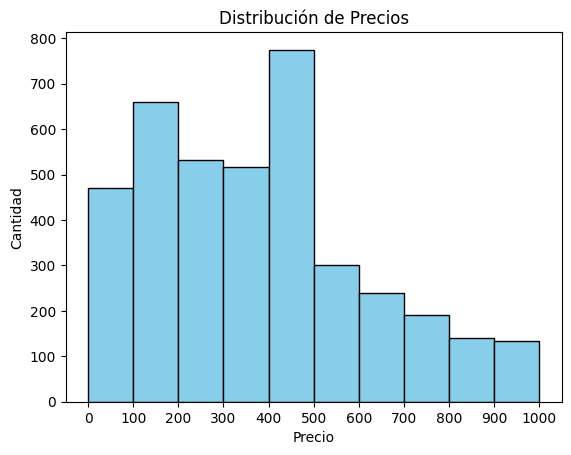

In [35]:
#Práctica Guiada 1: Analizando la distribución de precios
#Objetivo: El equipo de Inteligencia Comercial quiere entender cómo se distribuyen los precios y detectar posibles valores atípicos
#que puedan afectar los análisis.

import matplotlib.pyplot as plt
# Graficar histograma
counts, bin_edges, _ = plt.hist(
    df['price'],
    bins=10,
    range=(0,1000),
    color= 'skyblue',
    edgecolor='black'
)# Escribe tu código aquí

# Mostrar las marcas de los bins en el eje X
plt.xticks(bin_edges)# Escribe tu código aquí

# Etiquetas y título del gráfico
plt.xlabel("Precio")# tu código aquí)
plt.ylabel("Cantidad")# tu código aquí)
plt.title("Distribución de Precios")# tu código aquí)
plt.show()

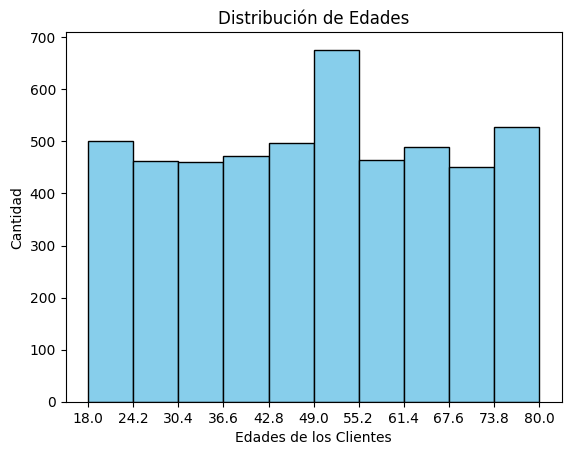

In [36]:
#Práctica Guiada 2: Distribución de edades de clientes
#Objetivo: El equipo quiere entender la distribución de las edades de los clientes (customer_age) para segmentar mejor
#las estrategias de marketing.

# Graficar histograma
counts, bin_edges, _ = plt.hist(
    df['customer_age'],
    bins= 10,
    color= 'skyblue',
    edgecolor= 'black'
)# tu código aquí

# Mostrar las marcas de los bins en el eje X
plt.xticks(bin_edges)# tu código aquí

# Etiquetas y título del gráfico
plt.xlabel("Edades de los Clientes")# tu código aquí)
plt.ylabel("Cantidad")# tu código aquí)
plt.title("Distribución de Edades")# tu código aquí)# tu código aquí
# tu código aquí

plt.show()

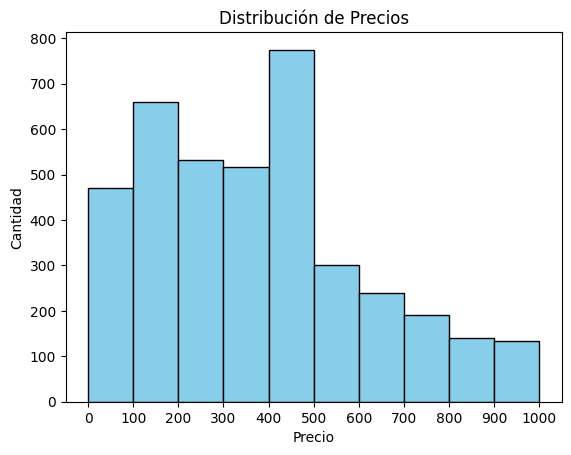

In [37]:
#Práctica Guiada 1: Analizando la distribución de precios
#Objetivo: El equipo de Inteligencia Comercial quiere entender cómo se distribuyen los precios y detectar posibles valores atípicos
#que puedan afectar los análisis.

# Graficar histograma
counts, bin_edges, _ = plt.hist(
    df['price'],
    range=(0,1000),
    bins=10,
    color='skyblue',
    edgecolor='black'
)
    # Escribe tu código aquí

# Mostrar las marcas de los bins en el eje X
plt.xticks(bin_edges)# Escribe tu código aquí

# Etiquetas y título del gráfico
plt.xlabel("Precio")# tu código aquí)
plt.ylabel("Cantidad")# tu código aquí)
plt.title("Distribución de Precios")# tu código aquí)
plt.show()



In [38]:
#instalar seaborn dentro del notebook
%pip install seaborn

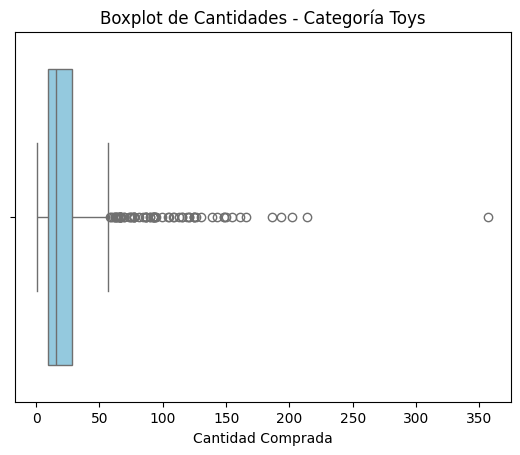

In [39]:
#Práctica Guiada 2: Explorando la dispersión de cantidades con Boxplot
#Objetivo: El equipo de Inteligencia Comercial necesita analizar cómo se distribuyen las cantidades compradas (quantity)
#dentro de la categoría "Toys", para detectar valores extremos que podrían afectar decisiones de inventario y logística.
import seaborn as sns

df_toys = df[df['product_category'] == 'Toys']# tu código aquí

# Graficar BoxPlot
sns.boxplot(x=df_toys['quantity'], color='skyblue')# tu código aquí)

# Etiquetas y título del gráfico
plt.xlabel("Cantidad Comprada")
plt.title("Boxplot de Cantidades - Categoría Toys")# tu código aquí

plt.show()


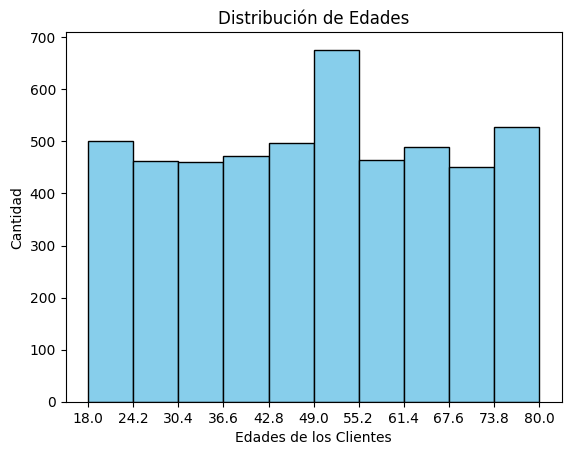

In [40]:
#Práctica Guiada 3: Distribución de edades de clientes
# Objetivo: El equipo quiere entender la distribución de las edades de los clientes (customer_age) para segmentar mejor
#las estrategias de marketing.

# Graficar histograma
counts, bin_edges, _ = plt.hist(
    df['customer_age'],
    bins= 10,
    color='skyblue',
    edgecolor='black'
)# tu código aquí

# Mostrar las marcas de los bins en el eje X
plt.xticks(bin_edges)# tu código aquí

# Etiquetas y título del gráfico
plt.xlabel("Edades de los Clientes")# tu código aquí)
plt.ylabel("Cantidad")# tu código aquí
plt.title("Distribución de Edades")# tu código aquí
plt.show()

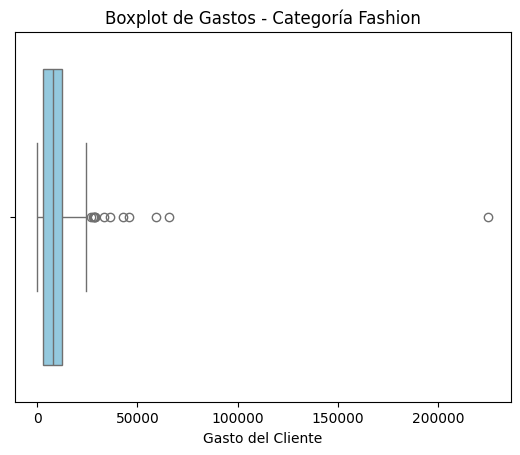

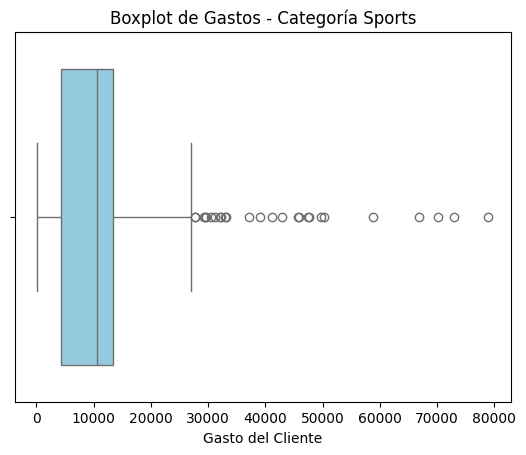

In [41]:
#Práctica Guiada 4: Boxplot del valor total de pedidos
# Objetivo: El equipo necesita analizar cuánto gastan los clientes en las categorías “Fashion” y “Sports”, evaluando la dispersión del order_value y detectando posibles outliers que puedan afectar
#decisiones de negocio.

# Filtrar datos
df_fashion = df[df['product_category']== 'Fashion']# Escribe tu código aquí
df_sports = df[df['product_category']=='Sports']# Escribe tu código aquí

# BoxPlot Categoría Fashion
sns.boxplot(x=df_fashion['order_value'],color='skyblue')# tu código aquí)
plt.xlabel("Gasto del Cliente")# tu código aquí)
plt.title("Boxplot de Gastos - Categoría Fashion")# tu código aquí)
plt.show()

# BoxPlot Categoría Sports
sns.boxplot(x=df_sports['order_value'],color='skyblue')# tu código aquí)
plt.xlabel("Gasto del Cliente")# tu código aquí)
plt.title("Boxplot de Gastos - Categoría Sports")# tu código aquí)
plt.show()

In [42]:
#Práctica Guiada 1 — Detectar outliers con IQR
#Objetivo: Identificar outliers en order_value con IQR.

#calcular Q1, Q3 e IQR
Q1 =df['order_value'].quantile(0.25) # tu código aquí
Q3 = df['order_value'].quantile(0.75)# tu código aquí
IQR = Q3 - Q1
 # tu código aquí

# calcular límite inferior y superior
limite_inferior = Q1 - 1.5 * IQR # tu código aquí
limite_superior = Q3 + 1.5 * IQR# tu código aquí

# Mostrar resultados
print('Primer cuartil: ', Q1)
print('Tercer cuartil: ', Q3)
print('IQR: ', IQR)

print("\nRegistros abajo del límite inferior")
print(df[df['order_value'] < limite_inferior]) # tu código aquí])

print("\nRegistros arriba del límite superior")
print(df[df['order_value'] > limite_superior]) # tu código aquí])

Primer cuartil:  3094.0
Tercer cuartil:  13160.5
IQR:  10066.5

Registros abajo del límite inferior
Empty DataFrame
Columns: [order_id, order_date, customer_id, product_category, price, quantity, order_value, payment_method, city, state, customer_age, quantity_invalid_flag, age_invalid_flag, state_missing_flag, order_value_imputed, customer_age_med, customer_age_mean]
Index: []

Registros arriba del límite superior
      order_id order_date  customer_id product_category   price  quantity  \
8            9 2024-03-14         2925           Beauty    55.0       833   
123        124 2024-06-21         1389      Electronics  1947.0        16   
155        156 2024-08-30         2901          Grocery    36.0      1278   
199        200 2024-12-18         2919          Fashion  5174.0         7   
265        266 2024-07-31         1905      Electronics  2897.0        10   
...        ...        ...          ...              ...     ...       ...   
4934      4935 2024-05-19         1502    

In [43]:
#Práctica Guiada 2 — Z-scores
#Objetivo: Identificar outliers en order_value usando Z-Score.

#cálculo de la media
mean = df['order_value'].mean()# tu código aquí

#cálculo de la desviación estándar
std =df['order_value'].std() # tu código aquí

#Crea el z score
df['z'] = (df['order_value']-mean)/std# tu código aquí

#Calcula los valores extremos
print(df[df['z'].abs()>3])# tu código aquí])
df['z'].describe()

      order_id order_date  customer_id product_category   price  quantity  \
293        294 2024-05-01         2149      Electronics  3336.0        17   
369        370 2024-10-09         2784      Electronics  5973.0        13   
375        376 2024-02-04         2285      Electronics  4782.0        20   
391        392 2024-03-06         2981      Electronics  2463.0        20   
397        398 2024-03-12         2024      Electronics  4893.0        18   
...        ...        ...          ...              ...     ...       ...   
4698      4699 2024-04-20         2059      Electronics  5227.0        11   
4732      4733 2024-10-06         2685           Sports  3394.0        14   
4908      4909 2024-10-19         1119      Electronics  3927.0        19   
4921      4922 2024-11-15         1621           Sports  2765.0        18   
4942      4943 2024-11-02         1979      Electronics  6478.0        11   

      order_value payment_method      city    state  customer_age  \
293   

,z
count,5.000000e+03
mean,-7.318590e-17
std,1.000000e+00
min,-8.111426e-01
25%,-5.627265e-01
50%,2.139798e-02
75%,2.486560e-01
max,2.367679e+01


In [44]:
#Práctica Individual 1 — Comparar métodos en price
#Objetivo: Comparar métodos IQR y Z-Score en la columna price.

# ----- IQR -----
# calcular Q1, Q3 e IQR
Q1 = df['price'].quantile(0.25)# tu código aquí
Q3 = df['price'].quantile(0.75) # tu código aquí
IQR =Q3-Q1 # tu código aquí

# calcular límite inferior y superior
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# ----- Z-score -----
# calcular media, desviación estándar y z-score
mean = df['price'].mean()# tu código aquí
std = df['price'].std() # tu código aquí
df['z'] =(df['price']-mean)/std # tu código aquí

# ----- Mostrar resultados -----
print('Outliers usando IQR:')
print(df[ (df['price']<lower) | (df['price']>upper)])

print('\nOutliers usando Z-Score:')
print(df[df['z'].abs()>3])

Outliers usando IQR:
      order_id order_date  customer_id product_category   price  quantity  \
64          65 2024-05-30         1651           Sports  2106.0         5   
67          68 2024-05-15         2385             Home  5181.0         4   
95          96 2024-04-15         2991           Sports  1940.0         4   
123        124 2024-06-21         1389      Electronics  1947.0        16   
138        139 2024-05-07         2274      Electronics  2437.0         6   
...        ...        ...          ...              ...     ...       ...   
4955      4956 2024-03-11         2230      Electronics  3824.0         6   
4974      4975 2024-10-20         2627      Electronics  1985.0         6   
4984      4985 2024-03-11         2509           Sports  1911.0         4   
4990      4991 2024-08-25         2569           Sports  2856.0         5   
4997      4998 2024-10-26         2838      Electronics  2699.0         4   

      order_value payment_method         city    state

In [45]:
#valores atípicos según el contexto
#Objetivo: Estabilizar los valores de la columna price

#calculo percentil 1 y 99
lower = df['price'].quantile(0.01)# tu código aquí
upper = df['price'].quantile(0.99)# tu código aquí
import numpy as np
#crear columna con valores capados
df['price_winsor'] = np.clip(df['price'],lower,upper)
print(df[['price','price_winsor']].head())
print(df[['price','price_winsor']].describe())

   price  price_winsor
0  269.0         269.0
1   66.0          66.0
2  267.0         267.0
3  114.0         114.0
4  729.0         729.0
              price  price_winsor
count   5000.000000   5000.000000
mean     756.290316    725.999316
std     1173.255143    877.247884
min       12.000000     32.000000
25%      218.000000    218.000000
50%      457.000000    457.000000
75%      847.000000    847.000000
max    36708.000000   5148.120000


In [46]:
#Práctica Guiada 1 — Escribir tu primer IF-ELSE
#La gerencia de marketing nos ha pedido crear una regla que indique si los clientes en general superan cierto volumen de compra.

# Calcular promedio y mediana
cantidad_promedio = df['quantity'].mean()# tu código aquí
cantidad_mediana = df['quantity'].median() # tu código aquí
print("Promedio:", cantidad_promedio)
print("Mediana:",cantidad_mediana)
print() # salto de línea

# Segmentación con media o promedio
if cantidad_promedio > 22:# tu código aquí
	print("En promedio: volumen alto")# tu código aquí)
else:
	print("En promedio: volumen bajo")# tu código aquí)

# Segmentación con mediana
if cantidad_mediana >22:
    print("Según la mediana: volumen alto")
else:
    print("Según la mediana: volumen bajo")# tu código aquí

Promedio: 32.3598
Mediana: 14.0

En promedio: volumen alto
Según la mediana: volumen bajo


In [47]:
#Práctica Individual 1 — Mejorar tu primer IF-ELSE
#La gerencia de marketing nos ha pedido mejorar la regla anterior agregando una tercera categoría.

# Calcular promedio y mediana
cantidad_promedio = df['quantity'].mean()
cantidad_mediana = df['quantity'].median()
print("Promedio:", cantidad_promedio)
print("Mediana:",cantidad_mediana)
print()

# Segmentación con media o promedio
if cantidad_promedio > 22:
	print("En promedio: volumen alto")
elif cantidad_promedio >= 10:
    print("En promedio: volumen medio")# tu código aquí

else:
	print("En promedio: volumen bajo")

# Segmentación con mediana
if cantidad_mediana > 22:
	print("Según la mediana: volumen alto")
elif cantidad_mediana >= 10:
    print("Según la mediana: volumen medio")## tu código aquí

else:
	print("Según la mediana: volumen bajo")

Promedio: 32.3598
Mediana: 14.0

En promedio: volumen alto
Según la mediana: volumen medio


In [48]:
#Práctica Guiada 1 — Segmentación básica con np.where()
#La gerencia de marketing nos ha pedido segmentar a los clientes por volumen de compra.

# Crear columna nueva
df["volume_segment"] = np.where(df["quantity"] > 22, "high_volume", "low_volume")# Completa el código

# Verificar cambios
print(df['volume_segment'].value_counts())

volume_segment
low_volume     3739
high_volume    1261
Name: count, dtype: int64


In [49]:
#Práctica Guiada 2 — Segmentación avanzada con función y apply
#Objetivo: La gerencia de marketing nos ha pedido segmentar los clientes por edad y por volumen de compra, separando en 4 segmentos.

def classify_volume(row):
    age = row['customer_age']# extrae la edad
    qty = row['quantity']# extrae la cantidad de compra

   # 1. Manejo de valores nulos/faltantes
    # pd.isna() verifica de forma robusta si el valor es NaN
    if pd.isna(age) or pd.isna(qty):
        return "Error en Datos"

    # --- 2. Segmentación de Altas Cantidades ---
    if qty > 22:
        if age > 55: # Completa el código: revisar edad mayor a 55 años
            return 'Sr. High Volume'# Completa el código
        else: # age <= 55
            return 'Jr. High Volume'# Completa el código

    # --- 3. Segmentación Bajas Cantidades ---
    elif qty <=22:# Completa el código: revisar cantidad menor o igual a 22
        if age> 55: # Completa el código: revisar edad mayor a 55 años
            return 'Sr. Low Volume'# Completa el código
        else: # age < 55
            return 'Jr. Low Volume'# Completa el código

# aplicar función y verificar cambios
df["volume_segment"] = df.apply(classify_volume,axis=1)# Completa el código)
print(df['volume_segment'].value_counts())

volume_segment
Jr. Low Volume     3004
Sr. High Volume    1197
Sr. Low Volume      735
Jr. High Volume      64
Name: count, dtype: int64


In [50]:
#Práctica Individual 1 — Segmentación avanzada con función y apply
#Objetivo: La gerencia de finanzas nos ha solicitado segmentar las transacciones según el método de pago y el volumen de compra,
#para analizar patrones de pago en compras altas y bajas.

def classify_payment(row):
    card = row['payment_method']# Completa el código
    qty = row['quantity'] # Completa el código

    # 1. Manejo de valores nulos/faltantes
    if pd.isna(card) or pd.isna(qty):
        return "Error en Datos"

    # --- 2. Segmentación de Altas Cantidades ---
    if qty > 22:
        if card == 'credit_card' or card == 'debit_card':# Completa el código
            return 'card_high_volume' # Completa el código
        else:
            return 'no_card_high_volume'# Completa el código

    # --- 3. Segmentación Bajas Cantidades ---
    elif qty <= 22:
        if card == 'credit_card'or card == 'debit_card':# Completa el código
            return 'card_low_volume'# Completa el código
        else:
         return 'no_card_low_volume'# Completa el código

# aplicar función y verificar cambios
df['payment_segment'] = df.apply(classify_payment,axis=1)# Completa el código)
print(df['payment_segment'].value_counts())

payment_segment
card_low_volume        2704
no_card_low_volume     1035
card_high_volume        922
no_card_high_volume     339
Name: count, dtype: int64
